# Registration

Each pair: the 64mT scan (moving) is registered to the 3T scan (fixed) with
`mri_synthmorph register -m rigid`, 6 DOF (3 rotations + 3 translations), on the raw grayscale
images, never on the label maps. One `.lta` per pair, against 3T lowres and 3T highres.

In [1]:
import pandas as pd

from common import OLD_OUT, LOGS, THREADS, fs

REG = OLD_OUT / 'reg'

## Register and save

Each `.lta` is written to the results folder as soon as it is computed; existing ones are skipped.

In [2]:
for acq in ['lowres', 'highres']:
    pairs = pd.read_csv(REG / f'pairs_{acq}.csv', keep_default_na=False)
    xfm = REG / f'xfm_{acq}'
    xfm.mkdir(parents=True, exist_ok=True)
    for r in pairs.itertuples():
        lta = xfm / f'{r.pair_id}.lta'
        if lta.exists() and lta.stat().st_size > 0:
            continue
        print(r.pair_id)
        fs(f'export OMP_NUM_THREADS={THREADS} && '
           f'mri_synthmorph register -m rigid -t {lta} {r.mov_raw} {r.fix_raw}',
           log=LOGS / f'register_old_{acq}.log', show=False)

    n = sum((xfm / f'{p}.lta').exists() for p in pairs.pair_id)
    assert n == len(pairs), f'{acq}: {n} / {len(pairs)} transforms'
    print(f'{acq}: {n} transforms -> {xfm}')

lowres: 61 transforms -> /home/jovyan/neurodesktop-storage/lfbook/results/old/reg/xfm_lowres
highres: 61 transforms -> /home/jovyan/neurodesktop-storage/lfbook/results/old/reg/xfm_highres


## Registration Quality Check

A visual check of the transforms: each 64mT scan is moved onto its 3T scan with the pair's
`.lta` (`mri_vol2vol`, trilinear) and drawn in semi-transparent red over the 3T scan in gray.

The examples are the pairs with the largest rotation in the transform, i.e. where the head was
tilted most differently in the two scanners: the hardest cases for a rigid registration. Two
per contrast (T1w, T2w, FLAIR), each from a different subject, against 3T lowres.

In [3]:
from pathlib import Path

import nibabel as nib
import numpy as np


def rotation_deg(lta):
    """Rotation angle (degrees) of the rigid transform in an .lta file."""
    lines = Path(lta).read_text().splitlines()
    i = lines.index('1 4 4')
    R = np.loadtxt(lines[i + 1:i + 4])[:, :3]
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))


ACQ, PER_MOD = 'lowres', 2            # 3T resolution; examples per modality
xfm, QC = REG / f'xfm_{ACQ}', REG / 'qc'
QC.mkdir(exist_ok=True)
pairs = pd.read_csv(REG / f'pairs_{ACQ}.csv', keep_default_na=False)
pairs['angle'] = [rotation_deg(xfm / f'{p}.lta') for p in pairs.pair_id]

# largest rotations first; each subject once, PER_MOD per modality
examples, used = [], set()
for r in pairs.sort_values('angle', ascending=False).to_dict('records'):
    if r['subject'] not in used and sum(e['modality'] == r['modality'] for e in examples) < PER_MOD:
        examples.append(r)
        used.add(r['subject'])

for r in examples:
    r['moved'] = QC / f"{r['pair_id']}_on_3T.nii.gz"
    if not r['moved'].exists():
        fs(f"mri_vol2vol --mov {r['mov_raw']} --targ {r['fix_raw']} --lta {xfm / r['pair_id']}.lta "
           f"--trilin --o {r['moved']} --no-save-reg", log=LOGS / 'register_qc_old.log', show=False)

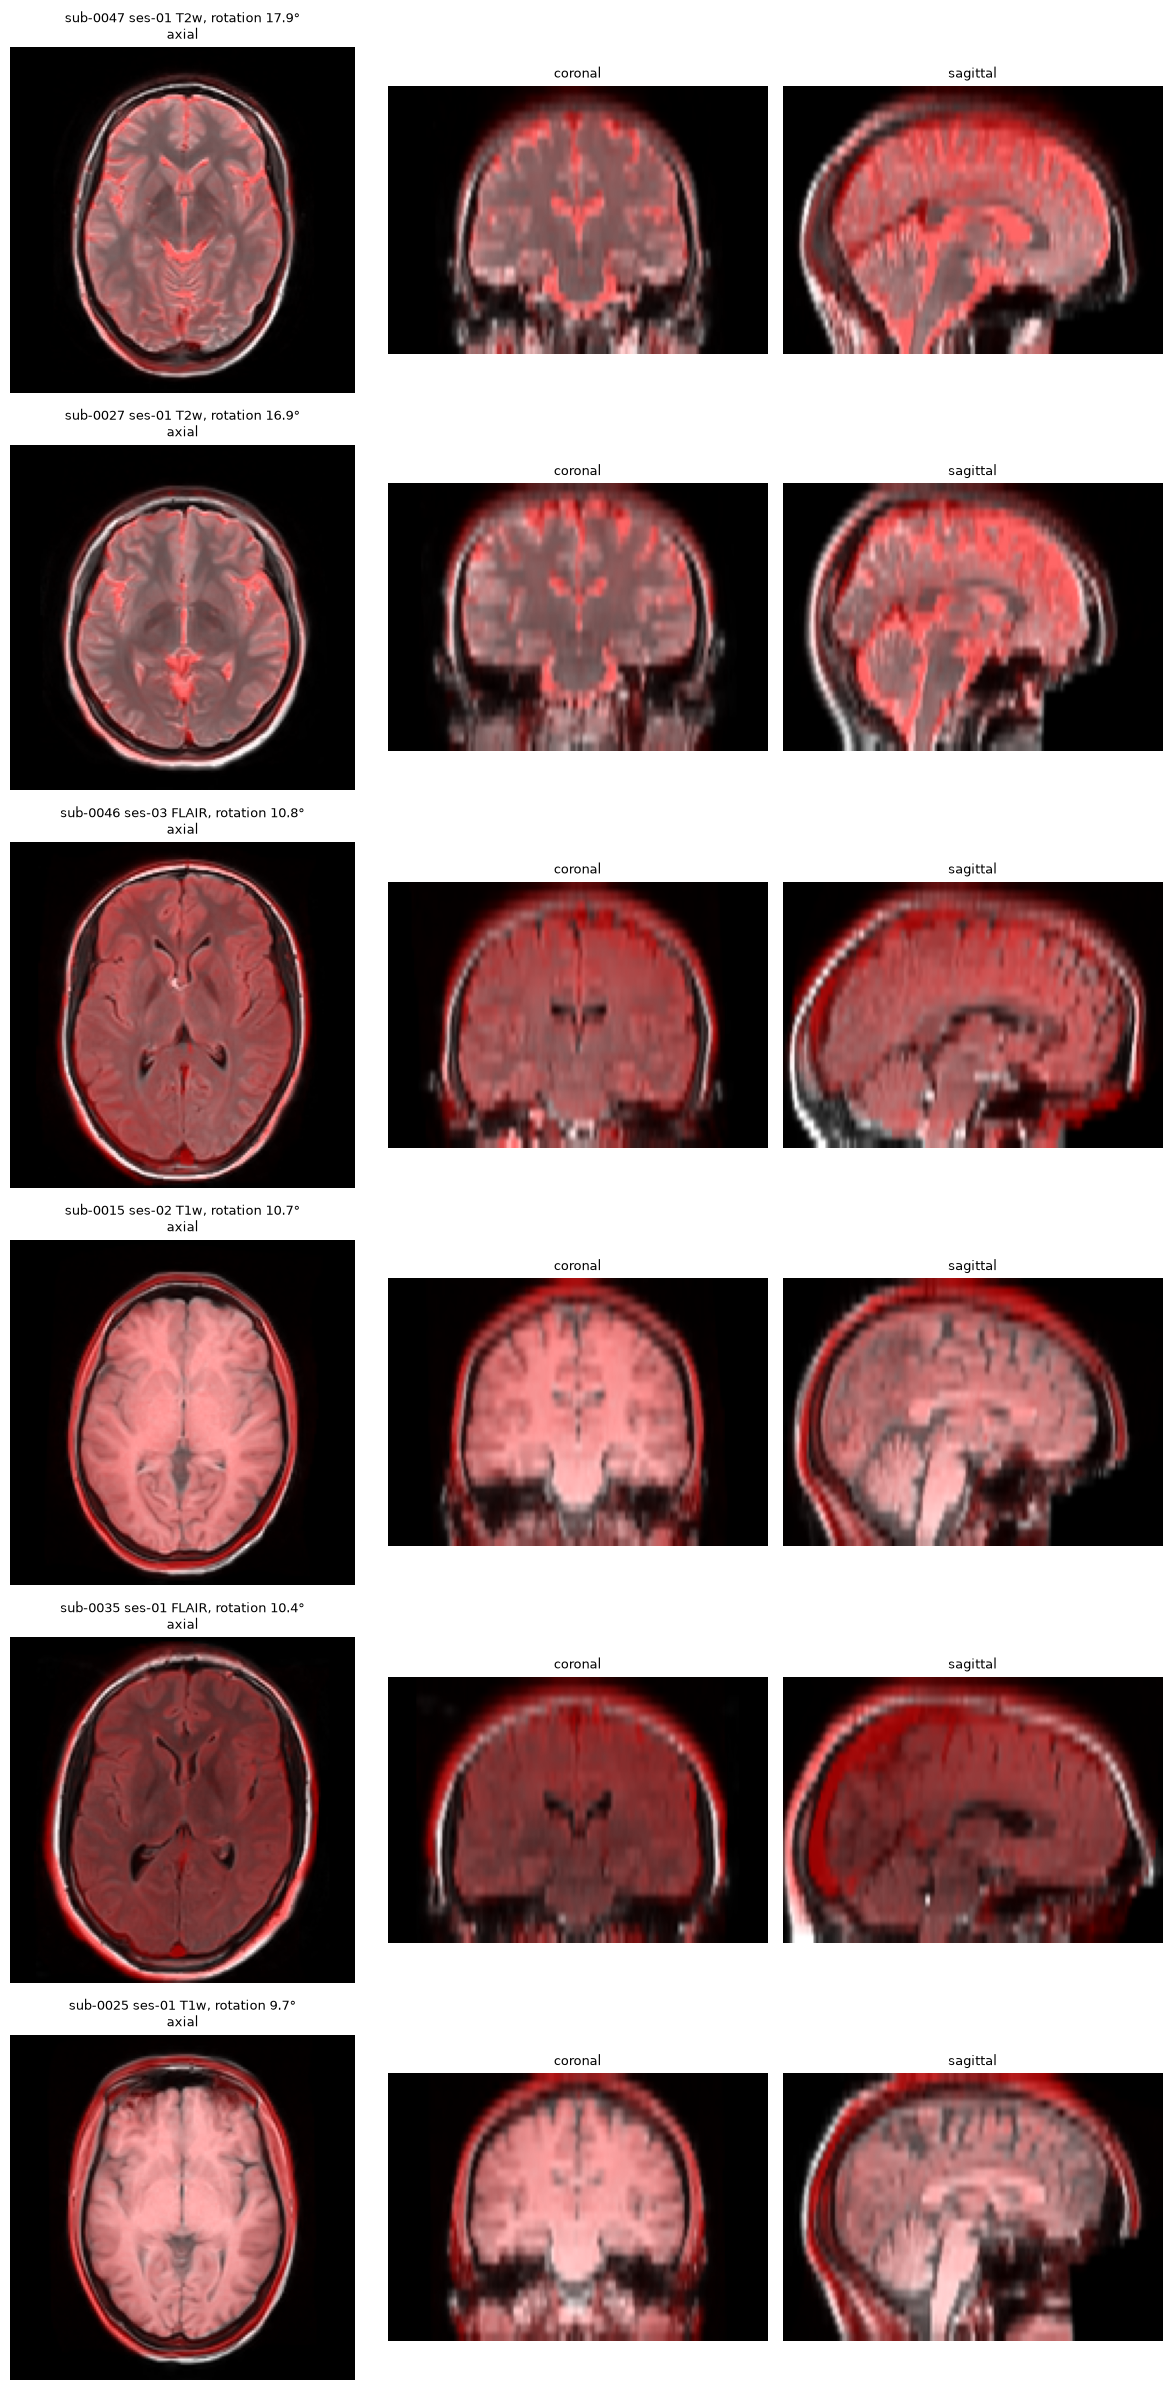

In [4]:
import matplotlib.pyplot as plt


def load_ras(path):
    """Image reoriented to R, A, S (no interpolation), and its voxel size."""
    img = nib.as_closest_canonical(nib.load(path))
    return np.asarray(img.dataobj, dtype=float), np.array(img.header.get_zooms()[:3])


def overlay(ax, hf, lf, vox, title):
    """3T in gray; 64mT in semi-transparent red (more opaque where the 64mT image is brighter)."""
    ext = (0, hf.shape[0] * vox[0], 0, hf.shape[1] * vox[1])
    ax.imshow(hf.T, cmap='gray', origin='lower', extent=ext, vmin=0, vmax=1)
    red = np.zeros(lf.T.shape + (4,))
    red[..., 0], red[..., 3] = 1, 0.6 * np.clip(lf.T, 0, 1)
    ax.imshow(red, origin='lower', extent=ext)
    ax.set_title(title, fontsize=9)
    ax.axis('off')


VIEWS = {'axial': (2, [0, 1]), 'coronal': (1, [0, 2]), 'sagittal': (0, [1, 2])}   # cut axis, shown axes
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 4 * len(examples)), squeeze=False)
for ax, r in zip(axes, examples):
    hf, vox = load_ras(r['fix_raw'])
    lf, _ = load_ras(r['moved'])
    hf, lf = hf / np.percentile(hf, 99), lf / np.percentile(lf[lf > 0], 99)
    centre = [int(np.average(np.arange(n), weights=hf.sum(axis=tuple(a for a in range(3) if a != d))))
              for d, n in enumerate(hf.shape)]                     # brain centre (intensity)
    for a, (view, (cut, shown)) in zip(ax, VIEWS.items()):
        sl = [slice(None)] * 3
        sl[cut] = centre[cut]
        name = f"{r['subject']} {r['session']} {r['modality']}, rotation {r['angle']:.1f}°\n" if view == 'axial' else '\n'
        overlay(a, hf[tuple(sl)], lf[tuple(sl)], vox[shown], name + view)
fig.tight_layout()